# 03 - Flood recession: how fast did the water drain?

Notebook 01 mapped the flood at its peak (12-13 September 2023). Here we follow the water over the next **3.5 months**
with every Sentinel-1 pass up to the end of December 2023.

**The problem:** each pass covers a different strip of the plain (~80-90% of the area), so raw km² from different passes
are not comparable.

**The solution:** for each pass we measure the **share of the peak flood extent that is still under water**, counting only the part of the
peak extent that this pass actually sees. A percentage does not depend on coverage, so all passes become comparable.

We also split the plain in two, because the two sides behaved very differently:
- **West**: Palamas, Karditsa (Pineios and its tributaries)
- **East**: Larissa and the old **Lake Karla** basin

In [1]:
import sys
from pathlib import Path
from datetime import date, timedelta
import ee
import geemap
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from pathlib import Path
# Your Earth Engine project id lives in project_id.txt (project root, not uploaded to GitHub)
_pid_file = Path.cwd().parent / "project_id.txt"
PROJECT_ID = _pid_file.read_text().strip() if _pid_file.exists() else "your-gcp-project-id"
ee.Initialize(project=PROJECT_ID)

ROOT = Path.cwd().parent
sys.path.append(str(ROOT))
from src.flood import get_aoi, s1_vv, flood_map, peak_flood

aoi = get_aoi()
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)

## 1. All Sentinel-1 passes after the storm

In [2]:
acq = (s1_vv(aoi).filterDate("2023-09-05", "2024-01-01")
       .reduceColumns(ee.Reducer.toList(3),
                      ["system:time_start", "relativeOrbitNumber_start", "orbitProperties_pass"])
       .get("list").getInfo())

acq = pd.DataFrame(acq, columns=["time", "orbit", "pass"])
acq["date"] = pd.to_datetime(acq["time"], unit="ms").dt.date
passes = (acq.groupby(["date", "orbit", "pass"]).size().rename("frames")
          .reset_index().sort_values("date").reset_index(drop=True))
print(f"{len(passes)} passes between {passes.date.min()} and {passes.date.max()}")
passes.head(10)

40 passes between 2023-09-06 and 2023-12-30


,date,orbit,pass,frames
0,2023-09-06,80,DESCENDING,2
1,2023-09-07,102,ASCENDING,2
2,2023-09-12,175,ASCENDING,2
3,2023-09-13,7,DESCENDING,2
4,2023-09-18,80,DESCENDING,2
5,2023-09-19,102,ASCENDING,2
6,2023-09-24,175,ASCENDING,2
7,2023-09-25,7,DESCENDING,2
8,2023-09-30,80,DESCENDING,2
9,2023-10-01,102,ASCENDING,2


## 2. Reference: the peak flood extent, split into West and East

The split is the meridian **22.30° E**, which runs through the gap between the two flooded areas.

In [3]:
SPLIT_LON = 22.30
SCALE = 30           # metres; enough for areas of tens of km² and much faster than 10 m

peak, _ = peak_flood(aoi)                      # 1 = flooded on 12 or 13 Sep, 0 = not
lon = ee.Image.pixelLonLat().select("longitude")
west, east = lon.lt(SPLIT_LON), lon.gte(SPLIT_LON)

def km2(img):
    """Sum of the area (km²) of every band of a 0/1 image."""
    return (img.multiply(ee.Image.pixelArea()).divide(1e6)
            .reduceRegion(ee.Reducer.sum(), aoi, SCALE, maxPixels=1e10).getInfo())

peak_km2 = km2(ee.Image.cat([peak.And(west), peak.And(east)]).rename(["west", "east"]))
peak_km2["total"] = peak_km2["west"] + peak_km2["east"]
{k: round(v, 1) for k, v in peak_km2.items()}

{'east': 216.7, 'west': 117.0, 'total': 333.8}

## 3. Flood map for every pass

For each pass we run the same method as in notebook 01 (`flood_map`, same orbit before and after) and measure, inside the peak extent:
- **seen**: peak-extent area inside this pass's footprint
- **wet**: of that, the area still flooded

`still flooded (%) = wet / seen`. A side is left empty (NaN) when the pass sees less than half of its peak extent.

We also record **new water** outside the peak extent (e.g. water that kept flowing into the Karla basin).
This one is in km² and depends on coverage, so it is only indicative.

In [4]:
MIN_SEEN = 0.5   # minimum share of a side's peak extent that a pass must see

rows = []
for _, p in passes.iterrows():
    d0 = p["date"].isoformat()
    d1 = (p["date"] + timedelta(days=1)).isoformat()
    flood, covered = flood_map(aoi, d0, d1)
    wet = flood.unmask(0)
    seen = covered.unmask(0)

    bands = ee.Image.cat([
        peak.And(seen).And(west), peak.And(seen).And(east),
        peak.And(wet).And(west),  peak.And(wet).And(east),
        wet.And(peak.Not()),
    ]).rename(["seen_w", "seen_e", "wet_w", "wet_e", "new_water"])
    r = km2(bands)

    row = {"date": p["date"], "orbit": p["orbit"], "pass": p["pass"], "new_water_km2": r["new_water"]}
    for side, s, w in [("west", "seen_w", "wet_w"), ("east", "seen_e", "wet_e")]:
        ok = r[s] >= MIN_SEEN * peak_km2[side]
        row[f"{side}_%"] = 100 * r[w] / r[s] if ok else float("nan")
    seen_tot, wet_tot = r["seen_w"] + r["seen_e"], r["wet_w"] + r["wet_e"]
    row["total_%"] = 100 * wet_tot / seen_tot if seen_tot >= MIN_SEEN * peak_km2["total"] else float("nan")
    rows.append(row)
    print(f"{d0}  orbit {p['orbit']:>3}  total {row['total_%']:5.1f}%")

ts = pd.DataFrame(rows).round(1)
ts["date"] = pd.to_datetime(ts["date"])
ts["remaining_km2"] = (ts["total_%"] / 100 * peak_km2["total"]).round(1)   # estimate for the whole plain
ts.to_csv(OUT / "recession_timeseries.csv", index=False)
ts

2023-09-06  orbit  80  total   3.0%
2023-09-07  orbit 102  total  55.8%
2023-09-12  orbit 175  total  94.1%
2023-09-13  orbit   7  total  88.2%
2023-09-18  orbit  80  total  36.5%
2023-09-19  orbit 102  total  41.9%
2023-09-24  orbit 175  total  16.9%
2023-09-25  orbit   7  total  30.5%
2023-09-30  orbit  80  total  38.5%
2023-10-01  orbit 102  total  48.8%
2023-10-06  orbit 175  total  18.4%
2023-10-07  orbit   7  total  39.4%
2023-10-12  orbit  80  total  28.4%
2023-10-13  orbit 102  total   nan%
2023-10-18  orbit 175  total  10.3%
2023-10-19  orbit   7  total  34.7%
2023-10-24  orbit  80  total  27.3%
2023-10-25  orbit 102  total  33.2%
2023-10-30  orbit 175  total  10.7%
2023-10-31  orbit   7  total  34.1%
2023-11-05  orbit  80  total  26.0%
2023-11-06  orbit 102  total  32.7%
2023-11-11  orbit 175  total   9.5%
2023-11-12  orbit   7  total  33.5%
2023-11-17  orbit  80  total  25.8%
2023-11-18  orbit 102  total  26.1%
2023-11-23  orbit 175  total   8.3%
2023-11-24  orbit   7  total

,date,orbit,pass,new_water_km2,west_%,east_%,total_%,remaining_km2
0,2023-09-06,80,DESCENDING,55.5,4.8,1.9,3.0,10.0
1,2023-09-07,102,ASCENDING,347.4,96.2,34.3,55.8,186.3
2,2023-09-12,175,ASCENDING,0.0,95.5,92.7,94.1,314.1
3,2023-09-13,7,DESCENDING,0.0,84.0,90.2,88.2,294.4
4,2023-09-18,80,DESCENDING,7.5,22.4,45.6,36.5,121.8
5,2023-09-19,102,ASCENDING,10.7,15.8,55.8,41.9,139.9
6,2023-09-24,175,ASCENDING,12.3,7.9,25.4,16.9,56.4
7,2023-09-25,7,DESCENDING,10.1,7.0,42.3,30.5,101.8
8,2023-09-30,80,DESCENDING,25.4,36.7,39.7,38.5,128.5
9,2023-10-01,102,ASCENDING,19.0,36.7,55.3,48.8,162.9


## 4. Recession curve, one line per orbit

The whole-plain curve zig-zags: values repeat in a 4-pass rhythm, which is the rhythm of the **4 relative orbits**, not of the water.
Each orbit sees the same strip every 12 days, so **within one orbit** the series is consistent. We therefore plot one line per orbit.

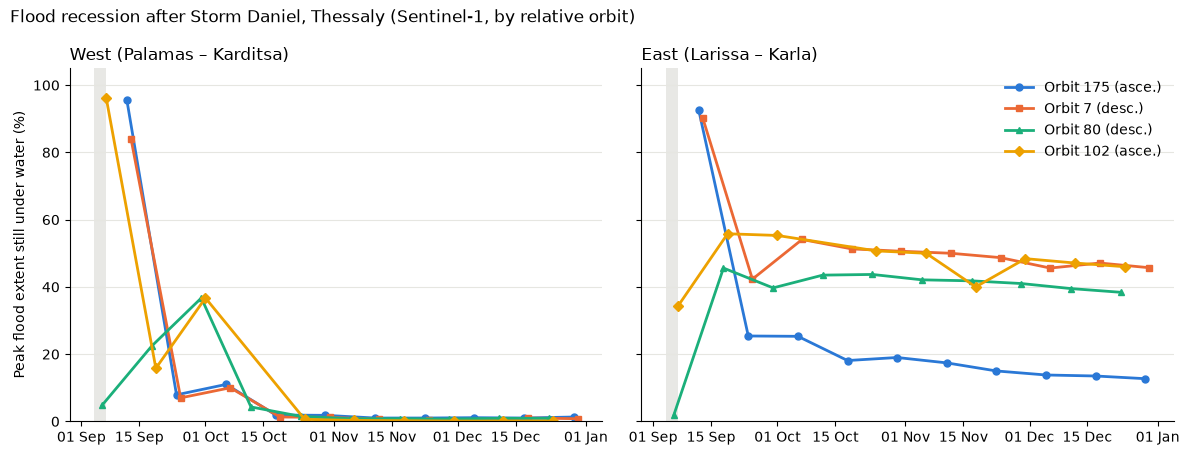

In [5]:
ts = pd.read_csv(OUT / "recession_timeseries.csv", parse_dates=["date"])

ORBIT_STYLE = {175: ("#2a78d6", "o"), 7: ("#eb6834", "s"), 80: ("#1baf7a", "^"), 102: ("#eda100", "D")}
ORBIT_NAME = {o: f"Orbit {o} ({ts.loc[ts.orbit == o, 'pass'].iloc[0].lower()[:4]}.)" for o in ORBIT_STYLE}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, side, title in [(axes[0], "west", "West (Palamas – Karditsa)"), (axes[1], "east", "East (Larissa – Karla)")]:
    for o, (col, mk) in ORBIT_STYLE.items():
        s = ts[(ts.orbit == o) & ts[f"{side}_%"].notna()]
        ax.plot(s["date"], s[f"{side}_%"], color=col, marker=mk, ms=5, lw=2, label=ORBIT_NAME[o])
    ax.axvspan(pd.Timestamp("2023-09-04"), pd.Timestamp("2023-09-07"), color="#d9d9d4", alpha=0.6, lw=0)
    ax.set_title(title, loc="left")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    ax.grid(axis="y", color="#e6e6e1", lw=0.8)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
axes[0].set_ylabel("Peak flood extent still under water (%)")
axes[0].set_ylim(0, 105)
axes[1].legend(frameon=False, loc="upper right")
fig.suptitle("Flood recession after Storm Daniel, Thessaly (Sentinel-1, by relative orbit)", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(OUT / "recession_curve_by_orbit.png", dpi=200)
plt.show()

## 5. Why do the orbits disagree in the East?

Two possible reasons:
1. **Different coverage**: an orbit that does not see the Karla basin only sees the part near Larissa, which drained quickly.
2. **Different viewing angle**: the same water can look darker or brighter at different incidence angles.

We test this on the **last pass of each orbit (late December)**, splitting the East into the **Karla basin** and the **rest (Larissa / Pineios)**.
If an orbit sees little of Karla, reason 1 explains the gap.

In [6]:
# Karla basin: 22.55–22.90 E, 39.35–39.60 N
lat = ee.Image.pixelLonLat().select("latitude")
karla = lon.gte(22.55).And(lon.lte(22.90)).And(lat.gte(39.35)).And(lat.lte(39.60))
east_rest = east.And(karla.Not())

zones = {"karla": karla, "east_rest": east_rest, "west": west}       # band names: letters, digits, _ only
ZONE_LABEL = {"karla": "Karla basin", "east_rest": "East, rest", "west": "West"}
zone_peak = km2(ee.Image.cat([peak.And(z) for z in zones.values()]).rename(list(zones)))

rows = []
for o in ORBIT_STYLE:
    d = passes[passes.orbit == o]["date"].iloc[-1]
    flood, covered = flood_map(aoi, d.isoformat(), (d + timedelta(days=1)).isoformat())
    seen, wet = covered.unmask(0), flood.unmask(0)
    names = [f"{z}_seen" for z in zones] + [f"{z}_wet" for z in zones]
    imgs = [peak.And(seen).And(z) for z in zones.values()] + [peak.And(wet).And(z) for z in zones.values()]
    r = km2(ee.Image.cat(imgs).rename(names))
    for z in zones:
        rows.append({"orbit": ORBIT_NAME[o], "date": d, "zone": ZONE_LABEL[z],
                     "seen_% of zone peak": 100 * r[f"{z}_seen"] / zone_peak[z],
                     "still flooded_%": 100 * r[f"{z}_wet"] / r[f"{z}_seen"] if r[f"{z}_seen"] > 1 else float("nan")})

diag = pd.DataFrame(rows).round(1)
print({ZONE_LABEL[z]: round(v, 1) for z, v in zone_peak.items()}, "km² at peak")
diag.pivot(index="orbit", columns="zone", values=["seen_% of zone peak", "still flooded_%"])

{'East, rest': 124.3, 'Karla basin': 92.5, 'West': 117.0} km² at peak


seen_% of zone peak                    still flooded_%  \
zone                       East, rest Karla basin   West      East, rest   
orbit                                                                      
Orbit 102 (asce.)               100.0       100.0   98.7            15.4   
Orbit 175 (asce.)                94.8         8.8  100.0            11.5   
Orbit 7 (desc.)                 100.0       100.0   92.5            14.8   
Orbit 80 (desc.)                 99.7        65.7  100.0            15.6   

                                    
zone              Karla basin West  
orbit                               
Orbit 102 (asce.)        87.1  0.1  
Orbit 175 (asce.)        30.8  1.3  
Orbit 7 (desc.)          87.3  0.8  
Orbit 80 (desc.)         84.8  0.9

## 5b. Key numbers (from the orbits that see each zone)

In [7]:
after_peak = ts[ts["date"] > "2023-09-13"]

def first_below(df, col, pct):
    hit = df[df[col] < pct]
    return hit["date"].iloc[0].date() if len(hit) else "not reached by 31 Dec"

rows = []
for o in ORBIT_STYLE:
    s = after_peak[after_peak.orbit == o]
    rows.append({"orbit": ORBIT_NAME[o],
                 "West below 10% on": first_below(s.dropna(subset=["west_%"]), "west_%", 10),
                 "West, last (%)": s["west_%"].dropna().iloc[-1] if s["west_%"].notna().any() else float("nan"),
                 "East below 50% on": first_below(s.dropna(subset=["east_%"]), "east_%", 50),
                 "East, last (%)": s["east_%"].dropna().iloc[-1] if s["east_%"].notna().any() else float("nan")})
pd.DataFrame(rows).set_index("orbit")

,West below 10% on,"West, last (%)",East below 50% on,"East, last (%)"
orbit,,,,
Orbit 175 (asce.),2023-09-24,1.3,2023-09-24,12.7
Orbit 7 (desc.),2023-09-25,0.8,2023-09-25,45.7
Orbit 80 (desc.),2023-10-12,0.9,2023-09-18,38.4
Orbit 102 (asce.),2023-10-25,0.1,2023-11-18,46.0


## 6. Map: the water on selected dates

Turn the layers on and off to watch the water drain. Each layer shows only what that pass covers.

In [8]:
SHOW = ["2023-09-25", "2023-10-07", "2023-10-31", "2023-11-24", "2023-12-18"]   # all orbit 7 (descending): same footprint
SHOW_COLORS = ["#08306b", "#2171b5", "#4292c6", "#6baed6", "#c6dbef"]

m = geemap.Map(center=[39.55, 22.25], zoom=9)
m.add_basemap("SATELLITE")
m.addLayer(peak.selfMask(), {"palette": ["#ffd700"]}, "Peak flood (12–13 Sep)")
for d, col in zip(SHOW, SHOW_COLORS):
    # nearest available pass on or after the chosen date
    p = passes[pd.to_datetime(passes["date"]) >= pd.Timestamp(d)].iloc[0]["date"]
    f, _ = flood_map(aoi, p.isoformat(), (p + timedelta(days=1)).isoformat())
    m.addLayer(f.selfMask(), {"palette": [col]}, f"Flood {p}", False)
m

Map(center=[39.55, 22.25], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright'…

## 7. Interpretation

| Zone | Peak extent | Still flooded, late December 2023 |
|---|---:|---:|
| West (Palamas – Karditsa) | 117 km² | **~1%** |
| East, Larissa / Pineios | 124 km² | **11–16%** |
| **Karla basin** | 93 km² | **85–87%** |

- **West: fast drainage.** Less than 10% of the peak extent was still flooded by 24-25 September, about 11 days after the peak.
  Two independent orbits (80 and 102) show a short second rise to ~37% around 1 October, most likely new water from the
  rain of Storm Elias (27-28 September 2023). From late October the area is dry (< 2%).
- **East: two very different behaviours.** The area along the Pineios near Larissa drained to 11-16%, but the **Karla basin stayed almost entirely
  under water for 3.5 months** (85-87% in all three orbits that see it). Karla is a closed depression, a former lake drained in the 1960s, so the
  water had no natural way out.
- **Why orbit 175 shows less water in the East:** it sees only **9% of the Karla basin**, so its "East" value describes mostly the Larissa area,
  which drained. A percentage only removes the coverage effect when the water is spread evenly, so comparisons are made **within one orbit**.

**Caveats**
- Late in the season, autumn rain and ploughed, wet fields can also lower backscatter; restricting the measure to the peak extent keeps this effect small.
- Shallow water among crops is partly missed (see notebook 02), so the percentages describe open water.